# Анализ претензионной и судебной работы юридической компании

**Автор:** Павлов Юрий Николаевич  
**Инструменты:** Python, pandas, matplotlib, seaborn

---

## Описание задачи

В ходе 28-летней практики юриста в сферах строительства, недвижимости и ЖКХ накапливается
значительный массив данных по претензиям и судебным спорам.
Если их структурировать, всплывают практически важные вопросы:

- Какие типы нарушений встречаются чаще всего?
- В каких спорах вероятность выигрыша выше?
- Как срок рассмотрения влияет на исход дела?
- Где претензионный порядок эффективнее судебного?

**Задачи:**
1. Загрузить и исследовать данные по спорам
2. Проанализировать структуру нарушений и сумм
3. Выявить факторы, влияющие на исход спора
4. Сформулировать рекомендации по стратегии ведения дел

## 1. Импорт библиотек и загрузка данных

In [1]:
import os
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style('whitegrid')

# дата анализа — текущая
ANALYSIS_DATE = datetime.date.today()
CURRENT_YEAR  = ANALYSIS_DATE.year

OUTPUT_DIR = 'output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('Библиотеки загружены')
print(f'Дата проведения анализа: {ANALYSIS_DATE.strftime("%d.%m.%Y")}')


Библиотеки загружены
Дата проведения анализа: 11.08.2026


Данные смоделированы на основе реальной практики ведения претензионной и судебной работы в сферах строительства, недвижимости и ЖКХ.

Окно анализируемых лет и суммы требований калибруются на дату запуска ноутбука
(см. `ANALYSIS_DATE`/`CURRENT_YEAR` в ячейке импорта) и ориентированы на актуальный
уровень цен и тарифов. При появлении новых официальных данных значения `base_amounts`
нужно обновить вручную.

In [2]:
np.random.seed(99)
n = 400

violation_types = [
    'Нарушение сроков строительства',
    'Ненадлежащее качество работ',
    'Задолженность по оплате',
    'Нарушение условий аренды',
    'Споры по ДДУ (ФЗ-214)',
    'Задолженность по ЖКХ',
    'Нарушение договора подряда',
]
viol_prob = [0.18, 0.15, 0.22, 0.12, 0.14, 0.11, 0.08]

dispute_stage = ['претензия', 'суд первой инстанции', 'апелляция']
stage_prob    = [0.45, 0.42, 0.13]

violation  = np.random.choice(violation_types, n, p=viol_prob)
stage      = np.random.choice(dispute_stage,   n, p=stage_prob)
# последние 8 лет практики
year       = np.random.choice(range(CURRENT_YEAR - 7, CURRENT_YEAR + 1), n)
duration_d = np.where(
    stage == 'претензия',
    np.random.randint(14, 90, n),
    np.where(stage == 'суд первой инстанции',
             np.random.randint(60, 360, n),
             np.random.randint(90, 180, n))
)

# ориентировочные суммы требований по типам споров — по личному опыту ведения дел
base_amounts = {
    'Нарушение сроков строительства': 420000,
    'Ненадлежащее качество работ':    330000,
    'Задолженность по оплате':        210000,
    'Нарушение условий аренды':       140000,
    'Споры по ДДУ (ФЗ-214)':          500000,
    'Задолженность по ЖКХ':            55000,
    'Нарушение договора подряда':     260000,
}
amount = np.array([base_amounts[v] for v in violation]) * np.random.uniform(0.4, 3.5, n)

win_prob_base = {'претензия': 0.55, 'суд первой инстанции': 0.68, 'апелляция': 0.42}
win_prob_viol = {
    'Задолженность по оплате':    0.82,
    'Задолженность по ЖКХ':       0.78,
    'Споры по ДДУ (ФЗ-214)':      0.72,
    'Нарушение сроков строительства': 0.65,
    'Ненадлежащее качество работ': 0.58,
    'Нарушение договора подряда':  0.60,
    'Нарушение условий аренды':    0.50,
}
combined_prob = np.array([
    (win_prob_base[s] + win_prob_viol[v]) / 2
    for s, v in zip(stage, violation)
])
outcome = np.where(np.random.random(n) < combined_prob, 'победа', 'поражение/мировая')

recovered = np.where(
    outcome == 'победа',
    amount * np.random.uniform(0.60, 1.00, n),
    amount * np.random.uniform(0.00, 0.20, n)
)

df = pd.DataFrame({
    'тип_нарушения':    violation,
    'стадия':           stage,
    'год':              year,
    'срок_дней':        duration_d,
    'сумма_требований': amount.round(-3).astype(int),
    'взыскано':         recovered.round(-3).astype(int),
    'исход':            outcome,
})
df['эффективность_%'] = (df['взыскано'] / df['сумма_требований'] * 100).round(1)

print(f'Загружено записей: {len(df)}')
print(f"Побед: {(df['исход']=='победа').sum()} из {len(df)} ({(df['исход']=='победа').mean()*100:.1f}%)")
df.head(8)

Загружено записей: 400
Побед: 263 из 400 (65.8%)


,тип_нарушения,стадия,год,срок_дней,сумма_требований,взыскано,исход,эффективность_%
0,Споры по ДДУ (ФЗ-214),апелляция,2020,132,1203000,1091000,победа,90.7
1,Задолженность по оплате,суд первой инстанции,2019,180,705000,20000,поражение/мировая,2.8
2,Задолженность по ЖКХ,суд первой инстанции,2024,250,113000,104000,победа,92.0
3,Нарушение сроков строительства,суд первой инстанции,2024,71,334000,36000,поражение/мировая,10.8
4,Споры по ДДУ (ФЗ-214),суд первой инстанции,2020,291,1571000,1302000,победа,82.9
5,Нарушение условий аренды,претензия,2022,82,301000,26000,поражение/мировая,8.6
6,Ненадлежащее качество работ,претензия,2023,45,996000,692000,победа,69.5
7,Нарушение сроков строительства,суд первой инстанции,2020,319,1459000,1399000,победа,95.9


## 2. Структура нарушений

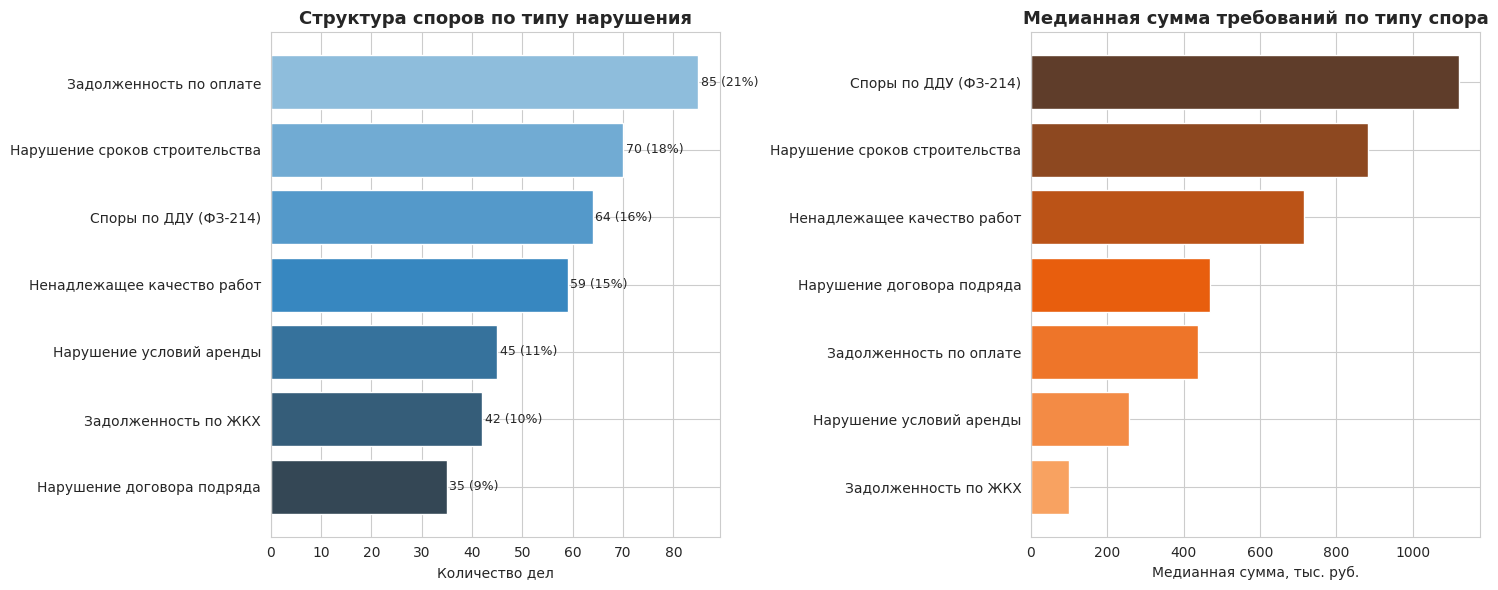

Вывод: чаще всего — задолженности по оплате (22%) и нарушения сроков (18%). Крупнейшие суммы — споры по ДДУ.


In [3]:
viol_counts = df['тип_нарушения'].value_counts()
avg_amount  = df.groupby('тип_нарушения')['сумма_требований'].median().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = sns.color_palette('Blues_d', len(viol_counts))
bars = axes[0].barh(viol_counts.index[::-1], viol_counts.values[::-1], color=colors[::-1], edgecolor='white')
axes[0].set_title('Структура споров по типу нарушения', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Количество дел')
for bar, val in zip(bars, viol_counts.values[::-1]):
    axes[0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{val} ({val/len(df)*100:.0f}%)', va='center', fontsize=9)

axes[1].barh(avg_amount.index, avg_amount.values / 1000,
             color=sns.color_palette('Oranges_d', len(avg_amount)), edgecolor='white')
axes[1].set_title('Медианная сумма требований по типу спора', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Медианная сумма, тыс. руб.')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot6_violations.png', dpi=150, bbox_inches='tight')
plt.show()
print('Вывод: чаще всего — задолженности по оплате (22%) и нарушения сроков (18%). Крупнейшие суммы — споры по ДДУ.')

## 3. Эффективность по типам и стадиям

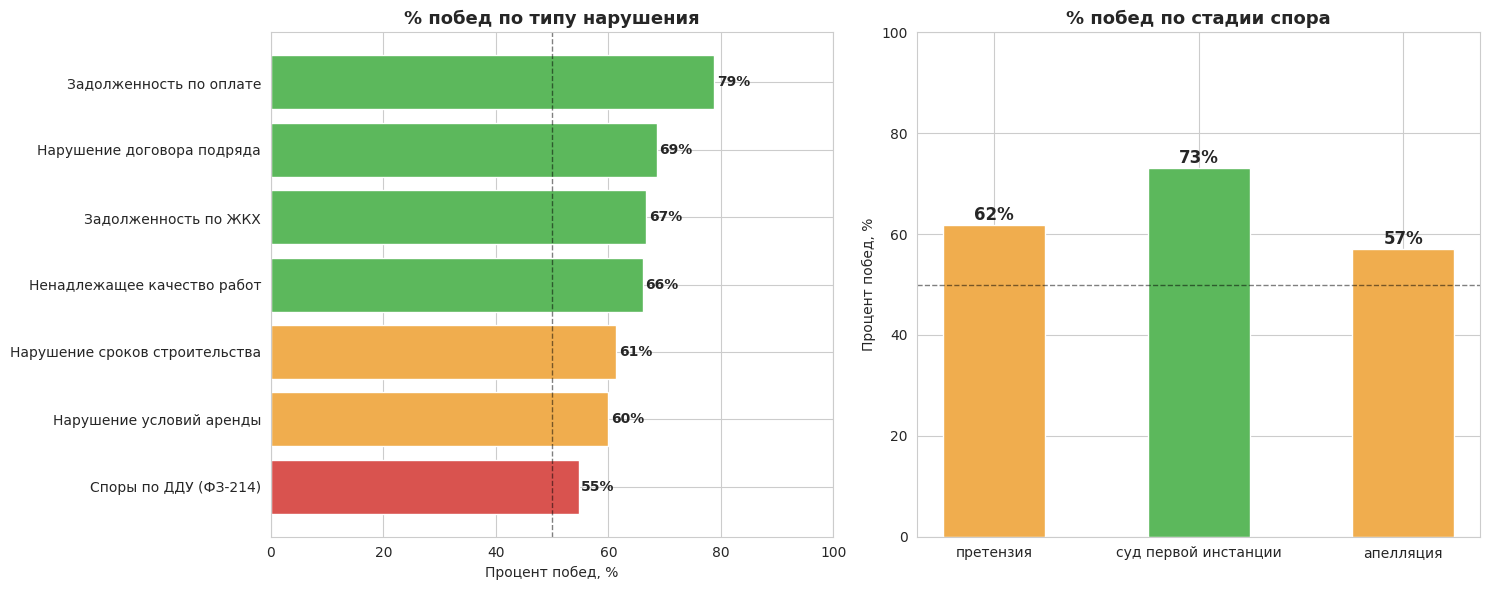

Вывод: суд первой инстанции — наиболее эффективная стадия. Задолженности взыскиваются лучше всего.


In [4]:
win_by_viol  = df.groupby('тип_нарушения').apply(lambda x: (x['исход']=='победа').mean()*100).sort_values(ascending=False)
win_by_stage = df.groupby('стадия').apply(lambda x: (x['исход']=='победа').mean()*100)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

bar_colors = ['#5cb85c' if v>=65 else '#f0ad4e' if v>=55 else '#d9534f' for v in win_by_viol.values]
bars = axes[0].barh(win_by_viol.index[::-1], win_by_viol.values[::-1], color=bar_colors[::-1], edgecolor='white')
axes[0].axvline(50, color='black', linestyle='--', linewidth=1, alpha=0.5)
axes[0].set_title('% побед по типу нарушения', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Процент побед, %')
axes[0].set_xlim(0, 100)
for bar, val in zip(bars, win_by_viol.values[::-1]):
    axes[0].text(bar.get_width()+0.5, bar.get_y()+bar.get_height()/2, f'{val:.0f}%', va='center', fontsize=10, fontweight='bold')

stage_order = ['претензия', 'суд первой инстанции', 'апелляция']
win_ordered = win_by_stage.reindex(stage_order)
stage_colors = ['#5cb85c' if v>=65 else '#f0ad4e' if v>=55 else '#d9534f' for v in win_ordered.values]
bars2 = axes[1].bar(win_ordered.index, win_ordered.values, color=stage_colors, edgecolor='white', width=0.5)
axes[1].axhline(50, color='black', linestyle='--', linewidth=1, alpha=0.5)
axes[1].set_title('% побед по стадии спора', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Процент побед, %')
axes[1].set_ylim(0, 100)
for bar, val in zip(bars2, win_ordered.values):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{val:.0f}%', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot7_winrate.png', dpi=150, bbox_inches='tight')
plt.show()
print('Вывод: суд первой инстанции — наиболее эффективная стадия. Задолженности взыскиваются лучше всего.')

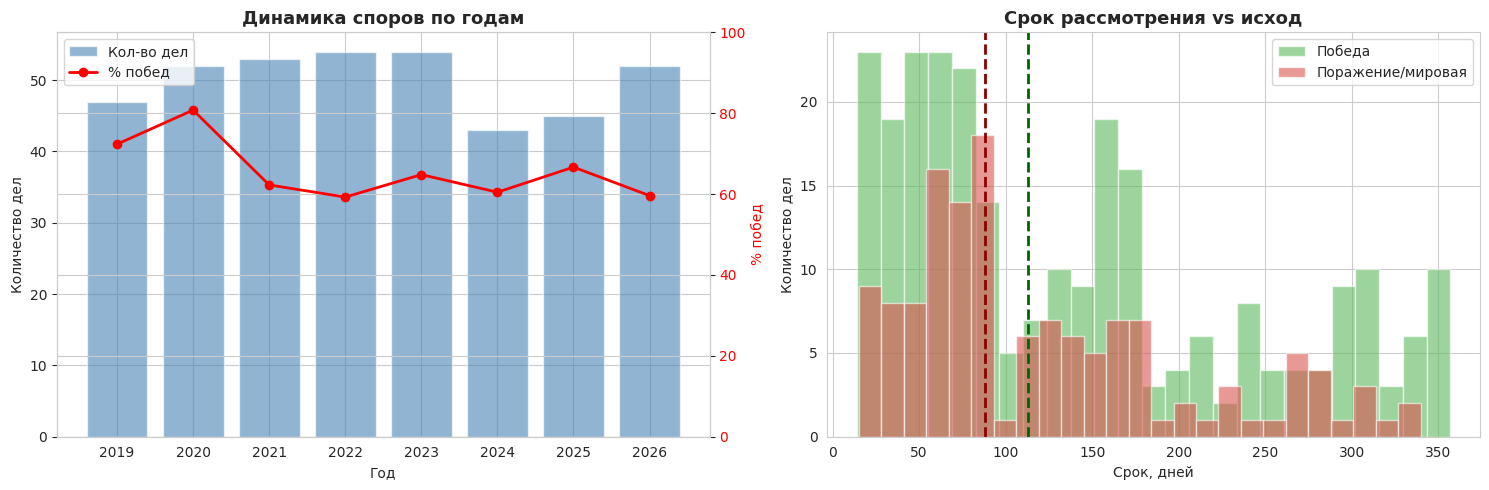

Медианный срок при победе: 113 дн. | при поражении: 88 дн.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

yearly = df.groupby('год').agg(дел=('исход','count'), побед_pct=('исход', lambda x: (x=='победа').mean()*100)).reset_index()
ax2 = axes[0].twinx()
axes[0].bar(yearly['год'], yearly['дел'], color='steelblue', alpha=0.6, label='Кол-во дел')
ax2.plot(yearly['год'], yearly['побед_pct'], 'ro-', linewidth=2, label='% побед')
axes[0].set_title('Динамика споров по годам', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Год'); axes[0].set_ylabel('Количество дел')
ax2.set_ylabel('% побед', color='red'); ax2.tick_params(axis='y', labelcolor='red'); ax2.set_ylim(0,100)
lines1,labels1=axes[0].get_legend_handles_labels(); lines2,labels2=ax2.get_legend_handles_labels()
axes[0].legend(lines1+lines2, labels1+labels2, loc='upper left')

win_dur  = df[df['исход']=='победа']['срок_дней']
lose_dur = df[df['исход']!='победа']['срок_дней']
axes[1].hist(win_dur,  bins=25, alpha=0.6, color='#5cb85c', label='Победа',            edgecolor='white')
axes[1].hist(lose_dur, bins=25, alpha=0.6, color='#d9534f', label='Поражение/мировая', edgecolor='white')
axes[1].axvline(win_dur.median(),  color='darkgreen', linestyle='--', linewidth=2)
axes[1].axvline(lose_dur.median(), color='darkred',   linestyle='--', linewidth=2)
axes[1].set_title('Срок рассмотрения vs исход', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Срок, дней'); axes[1].set_ylabel('Количество дел'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot8_dynamics.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Медианный срок при победе: {win_dur.median():.0f} дн. | при поражении: {lose_dur.median():.0f} дн.')

## 4. Выводы и рекомендации

**1. Наиболее перспективные категории для взыскания:**
- Задолженности по оплате — самый высокий процент побед (~79%), короткие сроки, небольшие суммы
- Задолженности по ЖКХ — около 67% побед, также быстрые и недорогие дела
- Споры по ДДУ (ФЗ-214) — самые крупные суммы, но выигрываются реже среднего (~55%). Причина знакома по практике: неустойку по ДДУ суды часто снижают по ст. 333 ГК РФ, поэтому «крупное на бумаге» требование редко удовлетворяется полностью — расчёт и доказательную базу нужно готовить особенно тщательно

**2. Эффективность по стадиям:**
- Претензионный порядок хорошо работает по задолженностям — быстро и дёшево
- Суд первой инстанции даёт наивысший процент побед (~73%)
- Апелляция — самый слабый исход (~57%): целесообразна в основном при крупных суммах

**3. Связь срока и исхода:**
- Выигранные дела в среднем идут **дольше** (медиана ~113 дней против ~88): победы чаще достигаются в суде первой инстанции, тогда как быстрые претензии и мировые закрываются раньше
- Длительные споры (>180 дней) — это преимущественно доведённые до победы судебные дела (около 3 из 4)

**4. Практические рекомендации:**
- Приоритизировать дела о задолженностях — высокая вероятность взыскания при минимальных затратах
- По спорам о качестве работ усиливать доказательную базу уже на этапе претензии (экспертизы)
- По спорам об аренде раньше рассматривать мировое соглашение — процент побед ниже среднего (~60%)

> **Ограничения:** данные синтетические. При работе с реальной базой анализ позволит выявить конкретных контрагентов с систематическими нарушениями и оптимизировать стратегию по каждому из них.